In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Konfigurasi dan Asumsi
Semua asumsi dikumpulkan di sini supaya mudah diubah dan dijelaskan di laporan.

- `NIM`: seed generator acak (hasil simulasi bisa diulang).
- `N_SCEN`: jumlah skenario simulasi (minimal 5.000).
- `PROFIT_MARGIN`: **asumsi** profit = persentase dari penjualan (Unit Price x Quantity). Kolom laba bawaan dataset memakai margin konstan, jadi margin ditentukan sendiri di sini.
- `TARGET_FACTOR`: target profit = faktor x rata-rata profit bulanan historis (1,05 berarti target 5% di atas rata-rata historis).

In [2]:
NIM = 301230043        # GANTI dengan NIM Anda
N_SCEN = 10_000        # jumlah skenario (minimal 5.000)
PROFIT_MARGIN = 0.10   # ASUMSI: profit = 10% dari penjualan
TARGET_FACTOR = 1.05   # target = 1,05 x rata-rata profit bulanan historis

rng = np.random.default_rng(NIM)

## Langkah 1: Eksplorasi Data Kaggle
### 1.1 Load data
Dataset: *Supermarket Sales* (Kaggle). Halaman asli `aungpyaeap/supermarket-sales` sudah tidak tersedia, sehingga dipakai salinan dengan isi sama (1.000 baris, 17 kolom, Januari sampai Maret 2019), misalnya `shandeep777/supermarket-dataset`. Sel di bawah mencoba, berurutan: file CSV yang sudah ada di folder kerja (cara paling mudah di VS Code), unduh otomatis lewat `kagglehub`, lalu unggah manual (hanya di Colab).

In [3]:
def load_data():
    # 1) file CSV yang sudah ada di folder kerja
    kandidat = glob.glob('*upermarket*ales*.csv') + glob.glob('/content/*upermarket*ales*.csv')
    if kandidat:
        print('Memakai file:', kandidat[0])
        return pd.read_csv(kandidat[0])
    # 2) unduh otomatis dari Kaggle
    try:
        import kagglehub
        for slug in ['shandeep777/supermarket-dataset',
                     'faresashraf1001/supermarket-sales',
                     'lovishbansal123/sales-of-a-supermarket',
                     'aungpyaeap/supermarket-sales']:
            try:
                path = kagglehub.dataset_download(slug)
                berkas = glob.glob(os.path.join(path, '*.csv'))[0]
                print('Diunduh dari Kaggle:', slug, '->', berkas)
                return pd.read_csv(berkas)
            except Exception as e:
                print('Gagal untuk', slug, '->', type(e).__name__)
    except Exception as e:
        print('Unduh otomatis gagal:', e)
    # 3) unggah manual (hanya di Google Colab)
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            'File CSV tidak ditemukan. Unduh dataset dari Kaggle, ekstrak, lalu '
            'letakkan file CSV (misal "supermarket_sales - Sheet1.csv") di folder '
            'yang sama dengan notebook ini, kemudian jalankan ulang sel ini.')
    up = files.upload()
    return pd.read_csv(list(up.keys())[0])

df = load_data()
# Samakan nama kolom (beda salinan bisa beda huruf besar/kecil)
df.columns = df.columns.str.strip()
df = df.rename(columns={c: {'unit price': 'Unit price', 'quantity': 'Quantity',
                            'date': 'Date'}[c.lower()]
                        for c in df.columns if c.lower() in ('unit price', 'quantity', 'date')})
print(df.shape)
df.head()

Memakai file: supermarket_sales - Sheet1.csv
(1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


### 1.2 Data cleaning
Menghapus data duplikat, nilai kosong, dan outlier ekstrem (aturan IQR dengan pengali 3).

In [4]:
n_awal = len(df)
df = df.drop_duplicates()
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Unit price', 'Quantity', 'Date'])
n_bersih_null = len(df)

def tanpa_outlier(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s.between(q1 - k * iqr, q3 + k * iqr)

mask = tanpa_outlier(df['Unit price']) & tanpa_outlier(df['Quantity'])
df = df[mask].copy()

print(f'Baris awal                     : {n_awal}')
print(f'Dibuang (duplikat/kosong)      : {n_awal - n_bersih_null}')
print(f'Dibuang (outlier ekstrem)      : {n_bersih_null - len(df)}')
print(f'Baris setelah cleaning         : {len(df)}')

Baris awal                     : 1000
Dibuang (duplikat/kosong)      : 0
Dibuang (outlier ekstrem)      : 0
Baris setelah cleaning         : 1000


### 1.3 Ekstraksi parameter (Mean dan Standar Deviasi)

In [5]:
harga = df['Unit price']
qty = df['Quantity']

ringkas = pd.DataFrame({
    'Mean': [harga.mean(), qty.mean()],
    'Std Dev': [harga.std(ddof=1), qty.std(ddof=1)],
    'Min': [harga.min(), qty.min()],
    'Max': [harga.max(), qty.max()],
}, index=['Unit price', 'Quantity']).round(4)
ringkas

,Mean,Std Dev,Min,Max
Unit price,55.6721,26.4946,10.08,99.96
Quantity,5.5100,2.9234,1.00,10.00


### 1.4 Histogram data asli
Bentuk histogram menentukan distribusi yang dipakai pada simulasi.

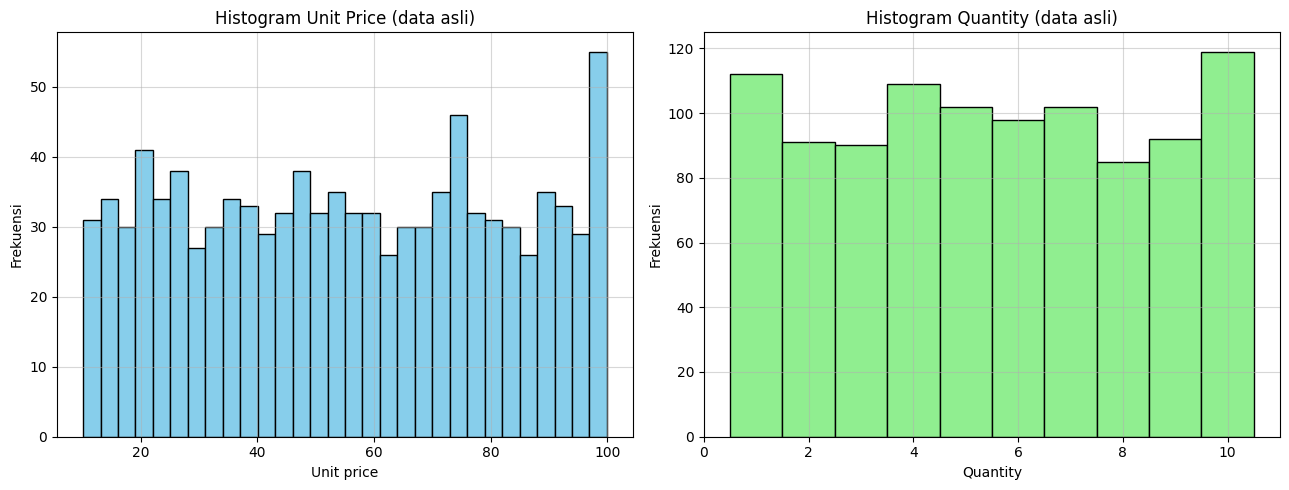

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].hist(harga, bins=30, color='skyblue', edgecolor='black')
ax[0].set_title('Histogram Unit Price (data asli)')
ax[0].set_xlabel('Unit price')
ax[0].set_ylabel('Frekuensi')
ax[0].grid(True, alpha=0.5)

ax[1].hist(qty, bins=np.arange(qty.min() - 0.5, qty.max() + 1.5, 1),
           color='lightgreen', edgecolor='black')
ax[1].set_title('Histogram Quantity (data asli)')
ax[1].set_xlabel('Quantity')
ax[1].set_ylabel('Frekuensi')
ax[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig('histogram_data_asli.png', dpi=150)
plt.show()

### 1.5 Memilih distribusi
Distribusi dipilih berdasarkan data, bukan ditebak: statistik Kolmogorov-Smirnov (KS) dihitung terhadap Normal dan Uniform, lalu dipilih yang **lebih kecil** (lebih cocok).

In [7]:
def pilih_distribusi(x):
    mu, sd = x.mean(), x.std(ddof=1)
    ks_normal = stats.kstest(x, 'norm', args=(mu, sd)).statistic
    ks_uniform = stats.kstest(x, 'uniform', args=(x.min(), x.max() - x.min())).statistic
    return ('uniform' if ks_uniform < ks_normal else 'normal'), ks_normal, ks_uniform

dist_harga, kn_h, ku_h = pilih_distribusi(harga)
dist_qty, kn_q, ku_q = pilih_distribusi(qty)

print(f'Unit price : KS Normal = {kn_h:.4f} | KS Uniform = {ku_h:.4f}  ->  {dist_harga}')
print(f'Quantity   : KS Normal = {kn_q:.4f} | KS Uniform = {ku_q:.4f}  ->  {dist_qty}')

Unit price : KS Normal = 0.0675 | KS Uniform = 0.0260  ->  uniform
Quantity   : KS Normal = 0.0993 | KS Uniform = 0.1190  ->  normal


### 1.6 Pola bulanan historis
Simulasi dilakukan per bulan, sehingga jumlah transaksi per bulan dan profit historis per bulan dihitung dari data.

In [8]:
df['Bulan'] = df['Date'].dt.to_period('M')
df['Penjualan'] = df['Unit price'] * df['Quantity']

bulanan = df.groupby('Bulan').agg(transaksi=('Penjualan', 'size'),
                                  penjualan=('Penjualan', 'sum'))
bulanan['profit'] = bulanan['penjualan'] * PROFIT_MARGIN

N_TX = int(round(bulanan['transaksi'].mean()))     # transaksi per bulan
PROFIT_HISTORIS = bulanan['profit'].mean()         # rata-rata profit bulanan
TARGET = TARGET_FACTOR * PROFIT_HISTORIS

print(bulanan.round(2))
print()
print(f'Rata-rata transaksi per bulan     : {N_TX}')
print(f'Rata-rata profit bulanan historis : {PROFIT_HISTORIS:,.2f}')
print(f'Target profit bulan depan         : {TARGET:,.2f}  ({TARGET_FACTOR}x historis)')

         transaksi  penjualan    profit
Bulan                                  
2019-01        352  110754.16  11075.42
2019-02        303   92589.88   9258.99
2019-03        345  104243.34  10424.33

Rata-rata transaksi per bulan     : 333
Rata-rata profit bulanan historis : 10,252.91
Target profit bulan depan         : 10,765.56  (1.05x historis)


## Langkah 2: Simulasi Monte Carlo
Satu skenario = satu bulan penjualan. Pada setiap skenario dibangkitkan `N_TX` transaksi. Tiap transaksi memiliki *Unit Price* dan *Quantity* acak dengan distribusi dan parameter dari Langkah 1. Profit skenario = `PROFIT_MARGIN` x jumlah (Unit Price x Quantity).

In [9]:
def bangkitkan(x, dist, ukuran, bulat=False):
    mu, sd, lo, hi = x.mean(), x.std(ddof=1), x.min(), x.max()
    if dist == 'normal':
        v = rng.normal(mu, sd, ukuran)
        v = np.clip(v, lo, hi)                  # batasi pada rentang data asli
        return np.rint(v) if bulat else v
    if bulat:
        return rng.integers(int(lo), int(hi) + 1, ukuran).astype(float)
    return rng.uniform(lo, hi, ukuran)

sim_harga = bangkitkan(harga, dist_harga, (N_SCEN, N_TX))
sim_qty = bangkitkan(qty, dist_qty, (N_SCEN, N_TX), bulat=True)

# Profit bulanan tiap skenario
profit_sim = (sim_harga * sim_qty).sum(axis=1) * PROFIT_MARGIN

print(f'Jumlah skenario : {N_SCEN}')
print(f'Transaksi/bulan : {N_TX}')
print(f'5 skenario awal : {np.round(profit_sim[:5], 2)}')

Jumlah skenario : 10000
Transaksi/bulan : 333
5 skenario awal : [ 9766.27 10159.09 10194.28  9641.45  9680.74]


## Langkah 3: Analisis Risiko dan Kesimpulan

In [10]:
rata_sim = profit_sim.mean()
std_sim = profit_sim.std(ddof=1)
p5, p95 = np.percentile(profit_sim, [5, 95])

# P(Event) = jumlah skenario yang memenuhi kondisi / total skenario
p_capai = np.sum(profit_sim >= TARGET) / N_SCEN
p_gagal = 1 - p_capai

print(f'Rata-rata profit simulasi : {rata_sim:,.2f}')
print(f'Rata-rata profit historis : {PROFIT_HISTORIS:,.2f}')
print(f'Std dev profit simulasi   : {std_sim:,.2f}')
print(f'Rentang 90% (P5 - P95)    : {p5:,.2f} - {p95:,.2f}')
print()
print(f'Target profit             : {TARGET:,.2f}')
print(f'P(profit >= target)       : {p_capai:.4f}  ({p_capai*100:.2f}%)')
print(f'P(profit <  target)       : {p_gagal:.4f}  ({p_gagal*100:.2f}%)')

Rata-rata profit simulasi : 10,089.11
Rata-rata profit historis : 10,252.91
Std dev profit simulasi   : 391.89
Rentang 90% (P5 - P95)    : 9,446.95 - 10,742.24

Target profit             : 10,765.56
P(profit >= target)       : 0.0444  (4.44%)
P(profit <  target)       : 0.9556  (95.56%)


### Analisis sensitivitas target
Probabilitas untuk beberapa tingkat target, supaya terlihat seberapa sensitif hasilnya.

In [11]:
baris = []
for f in [0.90, 0.95, 1.00, 1.05, 1.10, 1.15]:
    t = f * PROFIT_HISTORIS
    baris.append({'Faktor target': f, 'Target profit': round(t, 2),
                  'P(profit >= target)': round(np.mean(profit_sim >= t), 4)})
pd.DataFrame(baris)

,Faktor target,Target profit,P(profit >= target)
0,0.90,9227.62,0.9871
1,0.95,9740.27,0.8119
2,1.00,10252.91,0.3339
3,1.05,10765.56,0.0444
4,1.10,11278.20,0.0015
5,1.15,11790.85,0.0000


### Visualisasi hasil simulasi
Garis putus-putus merah menunjukkan target. Area di kiri garis adalah area risiko (profit di bawah target).

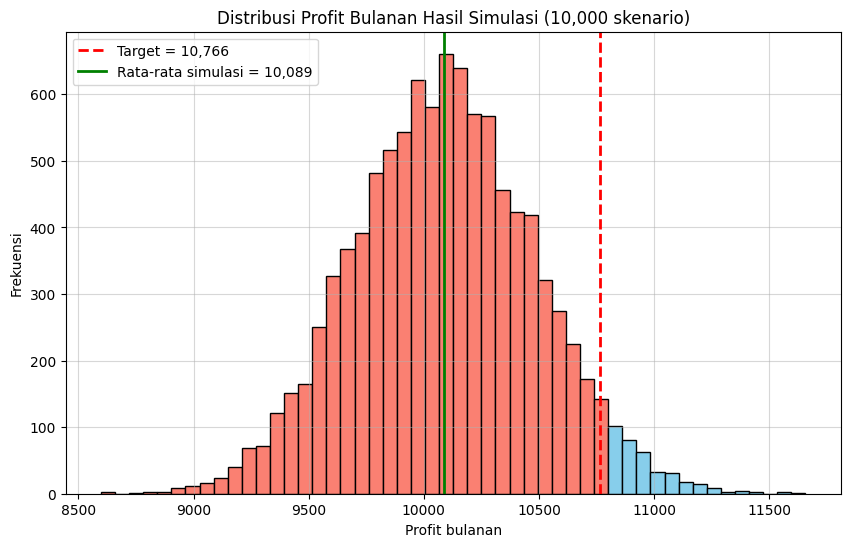

In [12]:
plt.figure(figsize=(10, 6))
n, bins, patches = plt.hist(profit_sim, bins=50, color='skyblue', edgecolor='black')
for b, p in zip(bins[:-1], patches):
    if b < TARGET:
        p.set_facecolor('salmon')
plt.axvline(TARGET, color='red', linestyle='--', linewidth=2,
            label=f'Target = {TARGET:,.0f}')
plt.axvline(rata_sim, color='green', linestyle='-', linewidth=2,
            label=f'Rata-rata simulasi = {rata_sim:,.0f}')
plt.title(f'Distribusi Profit Bulanan Hasil Simulasi ({N_SCEN:,} skenario)')
plt.xlabel('Profit bulanan')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig('histogram_hasil_simulasi.png', dpi=150)
plt.show()

### Kesimpulan

In [13]:
print(f'Berdasarkan {N_SCEN:,} skenario simulasi Monte Carlo, probabilitas toko mencapai')
print(f'target profit {TARGET:,.2f} bulan depan adalah {p_capai*100:.2f}%,')
print(f'sedangkan risiko tidak tercapai (profit di bawah target) sebesar {p_gagal*100:.2f}%.')
print(f'Rata-rata profit simulasi ({rata_sim:,.2f}) dibanding historis ({PROFIT_HISTORIS:,.2f}) ')
print(f'selisihnya {abs(rata_sim - PROFIT_HISTORIS) / PROFIT_HISTORIS * 100:.2f}%.')

Berdasarkan 10,000 skenario simulasi Monte Carlo, probabilitas toko mencapai
target profit 10,765.56 bulan depan adalah 4.44%,
sedangkan risiko tidak tercapai (profit di bawah target) sebesar 95.56%.
Rata-rata profit simulasi (10,089.11) dibanding historis (10,252.91) 
selisihnya 1.60%.


**Catatan keterbatasan:**
- Data hanya mencakup tiga bulan, sehingga pola musiman tidak tertangkap.
- Transaksi diasumsikan saling bebas, dan Unit Price dan Quantity dibangkitkan terpisah.
- Margin profit adalah asumsi (`PROFIT_MARGIN`); hasil probabilitas sensitif terhadap target dan margin ini.